# Motion Detection and Optical Flow

A shot detector splits a film into shots, but it says nothing about what happens inside them. A
chase differs from a dialogue mainly in how much and how fast things move. This notebook follows
the book section *Motion Detection* on "Tears of Steel". With a (nearly) static camera, we compare
frames with a background image and with each other, and accumulate the result in a motion history
image. With a moving camera, we estimate the optical flow with Lucas-Kanade, see why it needs
corners and a pyramid, and compare it with RAFT, a learned flow model. At the end, a simple motion
feature answers the query that the subtitles of the film cannot answer: the fight against the
robots.

**Learning goals:**
- Apply background subtraction, see its "ghosts", and see why it needs a camera that does not move
- Compare frame differencing with a small and a large gap, and remove the double image with
  three-frame differencing
- Build a motion history image and turn it into features
- Solve the Lucas-Kanade normal equations, on the book's example and on a real frame pair
- See the aperture problem in the eigenvalues, and see why large motions need a pyramid
- Compare Lucas-Kanade with RAFT, and rank the shots of the film by motion

**Prerequisites:** demo ch12-01 (the film and its shots); Chapter 10, section on edges (Sobel
gradients and corner points)

**Data:** "Tears of Steel" by the Blender Foundation (mango.blender.org), CC BY 3.0, downloaded on
first run to `data/tears_of_steel/` (see ch12-01). The RAFT weights (about 20 MB) are downloaded
by torchvision on first use.

**Run time:** about a minute with the caches of ch12-01; the first run also decodes the film once
more for the motion features (about half a minute).

## Setup

`ch12_video.py` holds the plumbing: decoding the film, the TransNet V2 shots of ch12-01, the fight
sequences of the film, and the RAFT model. Differencing, the motion history image, and
Lucas-Kanade are defined in this notebook.

In [1]:
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt

from shared.display import print_table, display_md
from ch12_video import (FPS, N_FRAMES, SMALL, ensure_film, decode, frames, frame, cached, tc,
                        frame_of, transnet_probabilities, transnet_transitions,
                        shots_from_transitions, is_fight, raft_flow, film_motion, show_frames)

ensure_film()
p, _ = transnet_probabilities()                       # cached by ch12-01
shots = shots_from_transitions(transnet_transitions(p))
display_md(f"{len(shots)} shots from TransNet V2 (see ch12-01).")

140 shots from TransNet V2 (see ch12-01).

## 1. A Nearly Static Camera

The differencing methods of the book assume a camera that never moves, such as a surveillance
camera above a parking lot. A feature film has no such shot. The closest one in "Tears of Steel"
is the breakup on the bridge from 0:25 to 0:40: the camera stays on Thom and Celia while they
talk and gesture. We decode the shot in gray at 640 by 267 pixels.

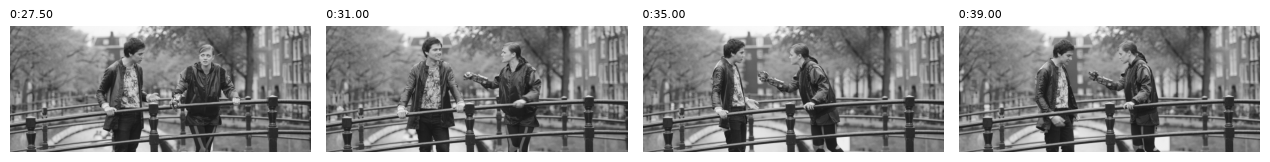

Shot 0:25.00 to 0:40.21: 366 frames of 640 by 267 pixels.

In [2]:
t_bridge = frame_of("0:30")
first, last = next((a, b) for a, b in shots if a <= t_bridge <= b)
G = frames(first, last - first + 1, size=(640, 267), pix_fmt="gray").astype(np.int16)

moments = [int(s * FPS) for s in (2.5, 6, 10, 14)]       # frames (relative to the shot start) we look at
show_frames([G[k] for k in moments], [f"{tc(first + k)}" for k in moments], ncols=4, width=3.2, cmap="gray")
display_md(f"Shot {tc(first)} to {tc(last)}: {len(G)} frames of {G.shape[2]} by {G.shape[1]} pixels.")

How static is the camera? Phase correlation estimates the global shift of a frame against the first
frame of the shot: the translation that best aligns the two images.

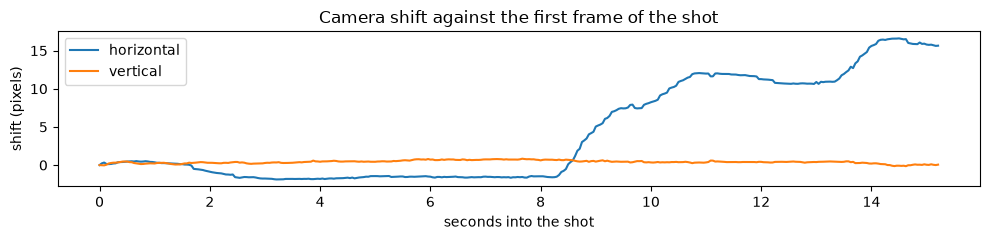

For the first 8.8 seconds, the camera moves by at most 2.1 pixels. By the end of the shot, it has drifted by 16 pixels.

In [3]:
shift = np.array([cv2.phaseCorrelate(G[0].astype(np.float32), g.astype(np.float32))[0] for g in G])
secs = np.arange(len(G)) / FPS

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.plot(secs, shift[:, 0], label="horizontal")
ax.plot(secs, shift[:, 1], label="vertical")
ax.set_xlabel("seconds into the shot")
ax.set_ylabel("shift (pixels)")
ax.set_title("Camera shift against the first frame of the shot")
ax.legend()
plt.tight_layout()
plt.show()

still = int(np.argmax(np.abs(shift[:, 0]) > 3))        # first frame that has moved by more than 3 pixels
display_md(f"For the first {still / FPS:.1f} seconds, the camera moves by at most "
           f"{np.abs(shift[:still]).max():.1f} pixels. By the end of the shot, it has drifted by "
           f"{np.abs(shift[-1, 0]):.0f} pixels.")

The first part of the shot is close to a static camera; the second part is not. Both parts are
useful: the first shows what the methods do, the second shows how they fail.

## 2. Background Subtraction

A pixel belongs to a moving object if it differs clearly from the background image:
$|B(x, y) - I(x, y, t)| > \tau$. There is no frame of the empty bridge, so we take the first frame
of the shot as $B$, actors included, and set $\tau = 30$ gray values.

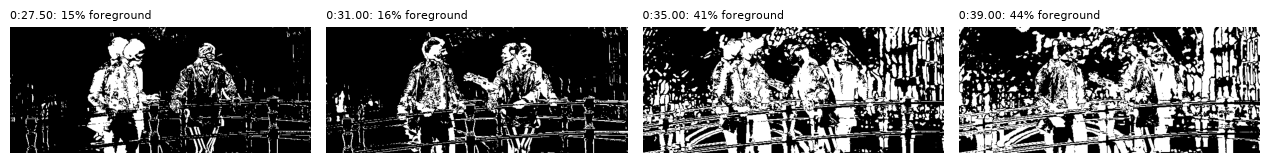

In [4]:
TAU = 30

def foreground(frame_gray, background, tau=TAU):
    """Foreground mask: pixels that differ from the background by more than tau."""
    return np.abs(frame_gray - background) > tau

B0 = G[0]
show_frames([foreground(G[k], B0) for k in moments],
            [f"{tc(first + k)}: {foreground(G[k], B0).mean():.0%} foreground" for k in moments],
            ncols=4, width=3.2, cmap="gray")

The first two masks show the actors, and some parts of them twice. Where Thom stood in the first
frame and has moved away since, the background image still contains him, and the empty place
appears as a second object: the "ghost" of the book. In the last two masks, the camera has moved,
every edge of the background is shifted against $B$, and the whole bridge counts as foreground.

### Updating the background

Practical systems blend the current frame into the background with a small weight $\alpha$, so the
background follows slow changes of the light: $B \leftarrow (1 - \alpha) B + \alpha I$. The book
applies the update only to pixels that are not part of a moving object. We compare three variants
over the whole shot.

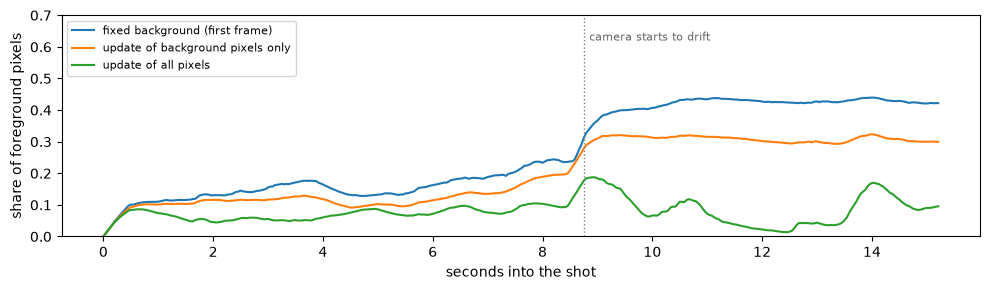

In [5]:
def subtract(G, tau=TAU, alpha=0.05, selective=True):
    """Background subtraction with a running background; returns the foreground share per frame and the masks."""
    B = G[0].astype(float)
    share, masks = [0.0], [np.zeros(G[0].shape, bool)]
    for g in G[1:]:
        m = foreground(g, B, tau)
        share.append(m.mean())
        masks.append(m)
        update = (1 - alpha) * B + alpha * g
        B = np.where(m, B, update) if selective else update
    return np.array(share), masks

share_fixed = np.array([foreground(g, B0).mean() for g in G])
share_sel, masks_sel = subtract(G, selective=True)
share_all, masks_all = subtract(G, selective=False)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(secs, share_fixed, label="fixed background (first frame)")
ax.plot(secs, share_sel, label="update of background pixels only")
ax.plot(secs, share_all, label="update of all pixels")
ax.axvline(still / FPS, color="0.5", ls=":", lw=1)
ax.text(still / FPS + 0.1, 0.62, "camera starts to drift", fontsize=8, color="0.4")
ax.set_xlabel("seconds into the shot")
ax.set_ylabel("share of foreground pixels")
ax.set_ylim(0, 0.7)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

With a fixed background, the foreground grows with the camera drift. The selective update
follows the slow changes before the drift, but after it, the foreground stays at about a third of
the image: the shifted background pixels count as foreground, and foreground pixels are never
updated, so the model locks in. Updating all pixels lets the background follow the camera,
but it also absorbs the actors whenever they stand still. A background model needs a camera that
does not move.

### Cleaning up the mask

A raw mask contains isolated noise pixels, and the objects break into pieces. A morphological
opening removes small specks, a closing fills small gaps, and the connected components of the
cleaned mask become a list of objects with a position and a size. We clean the mask of the
selective model at 2.5 seconds, before the camera drifts.

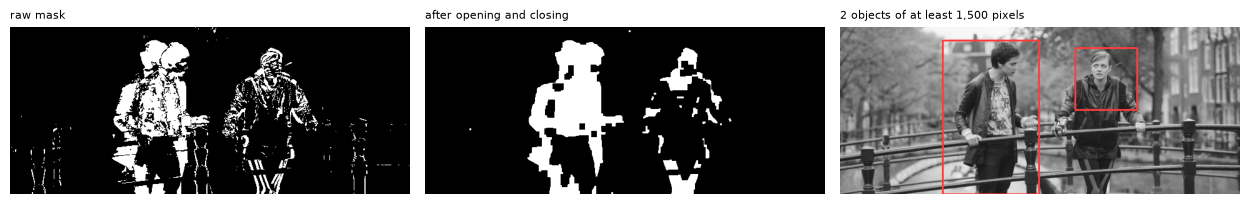

|   Object |   x |   y |   Width |   Height |   Pixels |
|---------:|----:|----:|--------:|---------:|---------:|
|        1 | 164 |  21 |     154 |      246 |    16079 |
|        2 | 376 |  33 |      99 |       99 |     2104 |

In [6]:
k = moments[0]
raw = masks_sel[k].astype(np.uint8)
clean = cv2.morphologyEx(raw, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
clean = cv2.morphologyEx(clean, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
n, labels, stats, _ = cv2.connectedComponentsWithStats(clean)
blobs = [s for s in stats[1:] if s[cv2.CC_STAT_AREA] >= 1500]          # ignore small components

boxed = cv2.cvtColor(G[k].astype(np.uint8), cv2.COLOR_GRAY2RGB)
for x, y, w, h, area in blobs:
    cv2.rectangle(boxed, (int(x), int(y)), (int(x + w), int(y + h)), (255, 60, 60), 2)
show_frames([raw * 255, clean * 255, boxed], ["raw mask", "after opening and closing",
            f"{len(blobs)} objects of at least 1,500 pixels"], ncols=3, width=4.2, cmap="gray")
print_table([[i + 1, int(x), int(y), int(w), int(h), int(a)] for i, (x, y, w, h, a) in enumerate(blobs)],
            ["Object", "x", "y", "Width", "Height", "Pixels"])

Thom, who has moved since the first frame, becomes one large object, together with his ghost.
Celia's mask breaks into pieces, and only the part around her head is large enough to count. The
size limit and the kernels decide what an object is, and they must fit the size of the objects
in the scene.

## 3. Frame Differencing

Instead of a background model, frame differencing compares each frame with an earlier one:
$|I(x, y, t - g) - I(x, y, t)| > \tau$. With a gap of $g = 1$ frame, the reference is only 1/24
second old. With a larger gap, the objects have moved further. Three-frame differencing compares
with a frame $g$ before and a frame $g$ after, and keeps the pixels that both masks mark.

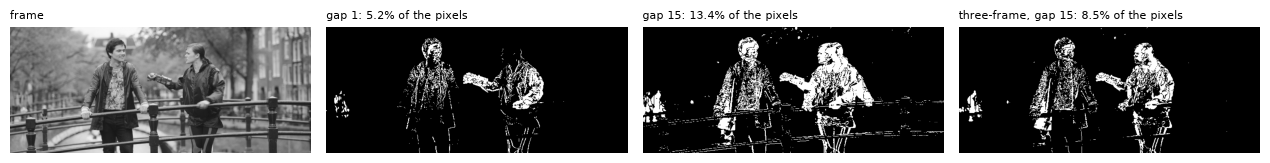

In [7]:
TAU_D = 15

def difference(G, t, gap, tau=TAU_D):
    """Frame differencing: pixels of frame t that differ from frame t - gap by more than tau."""
    return np.abs(G[t] - G[t - gap]) > tau

def three_frame(G, t, gap, tau=TAU_D):
    """Three-frame differencing: AND of the backward and the forward difference."""
    return difference(G, t, gap, tau) & (np.abs(G[t] - G[t + gap]) > tau)

t = moments[1]                        # 6 seconds into the shot, Celia gestures
views = [("frame", G[t]), ("gap 1", difference(G, t, 1)), ("gap 15", difference(G, t, 15)),
         ("three-frame, gap 15", three_frame(G, t, 15))]
show_frames([v for _, v in views],
            [name if name == "frame" else f"{name}: {v.mean():.1%} of the pixels" for name, v in views],
            ncols=4, width=3.2, cmap="gray")

With a gap of 1, the mask shows mainly the outlines of the moving parts: Celia's arm and the
edges of the two bodies. The inside of a uniform jacket keeps its value from one frame to the
next. With a gap of 15 frames, more of the outline differs, but each moving part appears twice,
at its old and at its new position. The AND of the backward and the forward difference keeps only
the position at time $t$. The price is a delay: the method needs frame $t + 15$, 0.6 seconds later.

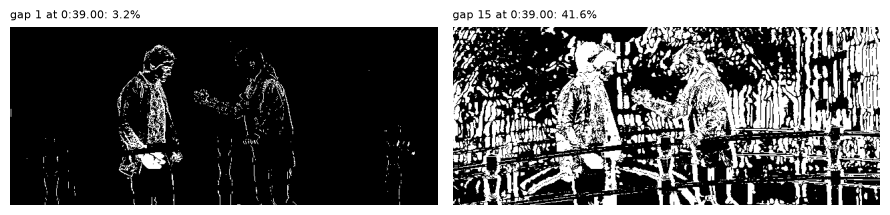

In [8]:
late = moments[3]                     # 14 seconds into the shot, the camera has drifted
show_frames([difference(G, late, 1), difference(G, late, 15)],
            [f"gap 1 at {tc(first + late)}: {difference(G, late, 1).mean():.1%}",
             f"gap 15 at {tc(first + late)}: {difference(G, late, 15).mean():.1%}"],
            ncols=2, width=4.5, cmap="gray")

After the camera has moved, frame differencing with a gap of 1 still works, because the camera
moves only a fraction of a pixel per frame. With a gap of 15, the drift adds up, and the edges of
the background appear in the mask. Frame differencing recovers from camera motion quickly, but it
does not ignore it.

## 4. Motion History Images

### The book's example: one pixel over eight frames

The motion history image keeps the most recent motion at full brightness and lets older motion
fade by $\gamma$ per frame: $M(t) = \max\big(D(t), \max(0, M(t-1) - \gamma)\big)$. The book follows
one pixel that a pedestrian crosses in frames 1 and 2, with $\gamma = 0.25$.

In [9]:
def update_mhi(M, D, gamma):
    """One step of the motion history image: new motion = 1, older motion fades by gamma."""
    return np.maximum(D.astype(float), np.maximum(0.0, M - gamma))

D_pixel = [0, 1, 1, 0, 0, 0, 0, 0]
M, history = 0.0, []
for D in D_pixel:
    M = update_mhi(M, np.array(D), 0.25)
    history.append(float(M))
print_table([["D(t)"] + D_pixel, ["M(t)"] + history], ["Frame t"] + list(range(8)), floatfmt=".2f")

| Frame t   |    0 |    1 |    2 |    3 |    4 |    5 |    6 |    7 |
|:----------|-----:|-----:|-----:|-----:|-----:|-----:|-----:|-----:|
| D(t)      | 0.00 | 1.00 | 1.00 | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 |
| M(t)      | 0.00 | 1.00 | 1.00 | 0.75 | 0.50 | 0.25 | 0.00 | 0.00 |

### On the bridge

We feed the frame-differencing masks with a gap of 1 into the motion history image, with
$\gamma = 1/24$, so the history covers one second.

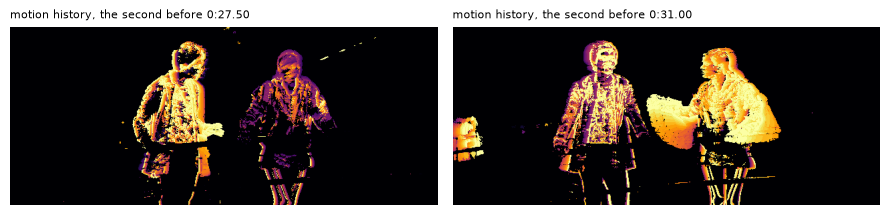

In [10]:
def motion_history(G, start, stop, gamma=1 / FPS, tau=TAU_D):
    """Motion history image after frames start..stop-1, from frame differencing with a gap of 1."""
    M = np.zeros(G[0].shape)
    for t in range(start, stop):
        M = update_mhi(M, difference(G, t, 1, tau), gamma)
    return M

mhis = [(k, motion_history(G, k - FPS, k)) for k in (moments[0], moments[1])]
show_frames([m for _, m in mhis], [f"motion history, the second before {tc(first + k)}" for k, _ in mhis],
            ncols=2, width=4.5, cmap="inferno")

Bright pixels moved in the last frames, dark red ones up to a second ago. The trail of Celia's arm
shows where it came from. For retrieval, the image becomes a feature vector: the share of pixels
that moved, the average recency of the motion, and the center of the moving region.

In [11]:
def mhi_features(M):
    """A few motion features from a motion history image."""
    moved = M > 0
    ys, xs = np.nonzero(moved)
    return [moved.mean(), M[moved].mean() if moved.any() else 0.0,
            xs.mean() / M.shape[1] if moved.any() else np.nan, ys.mean() / M.shape[0] if moved.any() else np.nan]

print_table([[tc(first + k)] + mhi_features(m) for k, m in mhis],
            ["Second before", "Share moved", "Mean recency", "Center x (0 left, 1 right)", "Center y (0 top)"],
            floatfmt=("", ".3f", ".2f", ".2f", ".2f"))

| Second before   |   Share moved |   Mean recency |   Center x (0 left, 1 right) |   Center y (0 top) |
|:----------------|--------------:|---------------:|-----------------------------:|-------------------:|
| 0:27.50         |         0.118 |           0.64 |                         0.50 |               0.48 |
| 0:31.00         |         0.192 |           0.77 |                         0.47 |               0.49 |

## 5. Optical Flow and the Lucas-Kanade Method

With a moving camera, every pixel changes. Optical flow estimates where each pixel moves. From
brightness constancy and a first-order Taylor expansion, every pixel gives one equation for its
motion $(u, v)$: $I_x u + I_y v = -I_t$. Lucas-Kanade assumes that all pixels in a small window
move together and solves the normal equations

$$\begin{bmatrix} \sum I_x^2 & \sum I_x I_y \\ \sum I_x I_y & \sum I_y^2 \end{bmatrix}
\begin{bmatrix} u \\ v \end{bmatrix} = \begin{bmatrix} -\sum I_x I_t \\ -\sum I_y I_t \end{bmatrix}$$

### The book's example: a corner and an edge

The book uses a window of 3 by 3 pixels on the corner of a bright object. We solve its system
and compute the eigenvalues of the matrix.

In [12]:
def solve_lk(Ix, Iy, It):
    """Lucas-Kanade for one window: the matrix A^T A, the right side, the motion (or None), the eigenvalues."""
    A = np.stack([np.ravel(Ix), np.ravel(Iy)], axis=1).astype(float)
    M, rhs = A.T @ A, -A.T @ np.ravel(It).astype(float)
    eig = np.linalg.eigvalsh(M)
    motion = np.linalg.solve(M, rhs) if eig[0] > 1e-9 * max(eig[1], 1) else None
    return M, rhs, motion, eig

Ix = [10, 10, 10, 8, 6, 4, 2, 0, 0]
Iy = [0, 0, 2, 4, 6, 8, 10, 10, 10]
It = [-10, -10, -12, -10, -9, -8, -7, -4, -5]
rows = []
for name, args in [("corner", (Ix, Iy, It)), ("vertical edge", ([10] * 9, [0] * 9, It))]:
    M, rhs, motion, eig = solve_lk(*args)
    rows.append([name, f"[[{M[0, 0]:.0f}, {M[0, 1]:.0f}], [{M[1, 0]:.0f}, {M[1, 1]:.0f}]]",
                 f"({rhs[0]:.0f}, {rhs[1]:.0f})", f"{eig[0]:.0f} and {eig[1]:.0f}",
                 "cannot be solved" if motion is None else f"u = {motion[0]:.3f}, v = {motion[1]:.3f}"])
print_table(rows, ["Window", "A^T A", "Right side", "Eigenvalues", "Motion (pixels per frame)"])

| Window        | A^T A                    | Right side   | Eigenvalues   | Motion (pixels per frame)   |
|:--------------|:-------------------------|:-------------|:--------------|:----------------------------|
| corner        | [[420, 140], [140, 420]] | (500, 342)   | 280 and 560   | u = 1.034, v = 0.470        |
| vertical edge | [[900, 0], [0, 0]]       | (750, 0)     | 0 and 900     | cannot be solved            |

At the corner, both eigenvalues are large, and the solution is close to the true motion $(1, 0.5)$
from which the book generated $I_t$. On the edge, one eigenvalue is 0: the matrix cannot be
inverted, and the motion along the edge stays unknown. This is the aperture problem in matrix form.

### A real frame pair

The book compares the methods on two consecutive frames at 4:30.8. The camera pans with Thom as he
walks, so the background moves by several pixels per frame. We compute the gradients with the
Sobel operator and the smaller eigenvalue of $\mathbf{A}^\top \mathbf{A}$ for a window of 5 by 5
pixels around every pixel: it is large only where the window contains gradients in two directions.

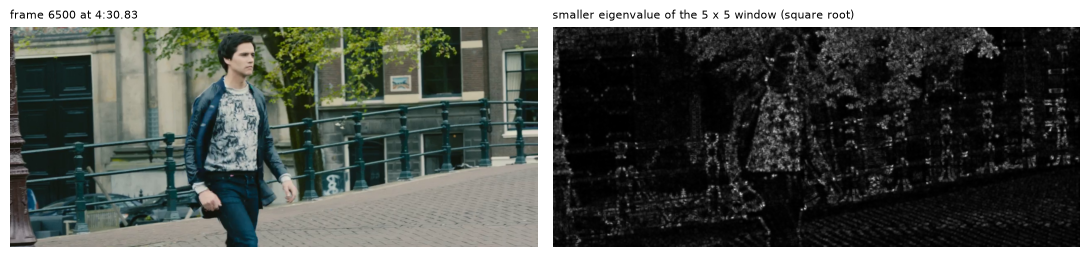

Share of the pixels whose smaller eigenvalue exceeds 1% of the maximum: 23.7%.

In [13]:
T_FLOW = frame_of("4:30.83")
f0, f1 = frame(T_FLOW), frame(T_FLOW + 1)
g0 = cv2.cvtColor(f0, cv2.COLOR_RGB2GRAY)
g1 = cv2.cvtColor(f1, cv2.COLOR_RGB2GRAY)

min_eig = cv2.cornerMinEigenVal(g0, blockSize=5, ksize=3)
show_frames([f0, np.sqrt(np.clip(min_eig, 0, None) / min_eig.max())],
            [f"frame {T_FLOW} at {tc(T_FLOW)}", "smaller eigenvalue of the 5 x 5 window (square root)"],
            ncols=2, width=5.5, cmap="gray")
display_md(f"Share of the pixels whose smaller eigenvalue exceeds 1% of the maximum: "
           f"{(min_eig > 0.01 * min_eig.max()).mean():.1%}.")

The dark door and the plain wall are black: there, Lucas-Kanade has nothing to solve. Long
straight edges, such as the bars of the railing, stay dark as well, because they have gradients in
only one direction. The patterned shirt, the leaves, and the window frames are bright; the
pavement is dim.

### Why large motions need a pyramid

The Taylor expansion holds for motions of about one pixel. We take the 500 strongest corners
(Shi-Tomasi, the same eigenvalue criterion), solve our own Lucas-Kanade with a 5 by 5 window at
each of them, and repeat on copies of both frames reduced by 2, 4, and 8. The estimate at a
reduced size is multiplied back to full-size pixels.

In [14]:
def lucas_kanade(I0, I1, x, y, half=2):
    """Single-level Lucas-Kanade at pixel (x, y) with a (2*half+1)^2 window; returns (u, v) or None."""
    I0, I1 = I0.astype(float), I1.astype(float)
    Ix = cv2.Sobel(I0, cv2.CV_64F, 1, 0, ksize=3) / 8
    Iy = cv2.Sobel(I0, cv2.CV_64F, 0, 1, ksize=3) / 8
    win = (slice(y - half, y + half + 1), slice(x - half, x + half + 1))
    return solve_lk(Ix[win], Iy[win], (I1 - I0)[win])[2]

corners = cv2.goodFeaturesToTrack(g0, maxCorners=500, qualityLevel=0.01, minDistance=10, blockSize=7).reshape(-1, 2)

rows = []
for s in (1, 2, 4, 8):
    size = (g0.shape[1] // s, g0.shape[0] // s)
    a0, a1 = (cv2.resize(g, size, interpolation=cv2.INTER_AREA) for g in (g0, g1))
    est = []
    for x, y in corners:
        xi, yi = int(round(x / s)), int(round(y / s))
        if 3 <= xi < size[0] - 3 and 3 <= yi < size[1] - 3:
            m = lucas_kanade(a0, a1, xi, yi)
            if m is not None:
                est.append(m * s)
    u, v = np.median(est, axis=0)
    rows.append([f"1/{s}" if s > 1 else "full size", f"{size[0]} x {size[1]}", len(est), u, v])
print_table(rows, ["Frame size", "Pixels", "Corners", "Median u (pixels)", "Median v (pixels)"],
            floatfmt=("", "", "", ".2f", ".2f"))

| Frame size   | Pixels     |   Corners |   Median u (pixels) |   Median v (pixels) |
|:-------------|:-----------|----------:|--------------------:|--------------------:|
| full size    | 1280 x 534 |       498 |               -0.80 |                0.43 |
| 1/2          | 640 x 267  |       493 |               -1.38 |                0.83 |
| 1/4          | 320 x 133  |       478 |               -3.33 |                1.59 |
| 1/8          | 160 x 66   |       451 |               -7.65 |                2.10 |

At full size, the background moves by about 8 pixels per frame, far beyond the linear range, and
the estimate is a fraction of the true motion. At one eighth of the size, the same motion is
about one pixel, and the estimate is close. A pyramidal Lucas-Kanade does exactly this: it starts
at the coarsest level and refines the estimate level by level.

## 6. Then vs. Now: Lucas-Kanade versus RAFT

OpenCV's pyramidal Lucas-Kanade tracks the corners over four levels with windows of 21 by 21
pixels, as in the book. RAFT (Teed and Deng, 2020) compares every pixel of the first frame with
every pixel of the second and estimates a vector for each pixel.

In [15]:
t0 = time.perf_counter()
pts = cv2.goodFeaturesToTrack(g0, maxCorners=500, qualityLevel=0.01, minDistance=10, blockSize=7)
nxt, status, _ = cv2.calcOpticalFlowPyrLK(g0, g1, pts, None, winSize=(21, 21), maxLevel=3,
                                          criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
lk_seconds = time.perf_counter() - t0
ok = status.ravel() == 1
p0 = pts.reshape(-1, 2)[ok]
v_lk = nxt.reshape(-1, 2)[ok] - p0

flow, raft_seconds = raft_flow(f0, f1)          # shape (2, height, width)

# compare at the tracked corners, and measure how much of the image the 21 x 21 windows cover
xi, yi = np.round(p0[:, 0]).astype(int), np.round(p0[:, 1]).astype(int)
diff = np.linalg.norm(v_lk - flow[:, yi, xi].T, axis=1)
covered = np.zeros(g0.shape, bool)
for x, y in zip(xi, yi):
    covered[max(0, y - 10):y + 11, max(0, x - 10):x + 11] = True

display_md(
    f"| | Lucas-Kanade (pyramid) | RAFT |\n|---|---|---|\n"
    f"| Vectors | {ok.sum()} of {len(pts)} corners tracked | {flow.shape[1] * flow.shape[2]:,} (every pixel) |\n"
    f"| Run time on the CPU | {lk_seconds * 1000:.0f} ms | {raft_seconds:.1f} s |\n"
    f"| Share of the image | {covered.mean():.0%} covered by the windows | 100% |\n"
    f"| Median motion | {np.median(np.linalg.norm(v_lk, axis=1)):.1f} pixels | {np.median(np.linalg.norm(flow, axis=0)):.1f} pixels |\n\n"
    f"At the tracked corners, the two vectors differ by {np.median(diff):.2f} pixels (median), and "
    f"{(diff < 1).mean():.0%} of the corners differ by less than one pixel."
)

| | Lucas-Kanade (pyramid) | RAFT |
|---|---|---|
| Vectors | 493 of 500 corners tracked | 683,520 (every pixel) |
| Run time on the CPU | 26 ms | 9.3 s |
| Share of the image | 24% covered by the windows | 100% |
| Median motion | 8.0 pixels | 8.8 pixels |

At the tracked corners, the two vectors differ by 0.26 pixels (median), and 84% of the corners differ by less than one pixel.

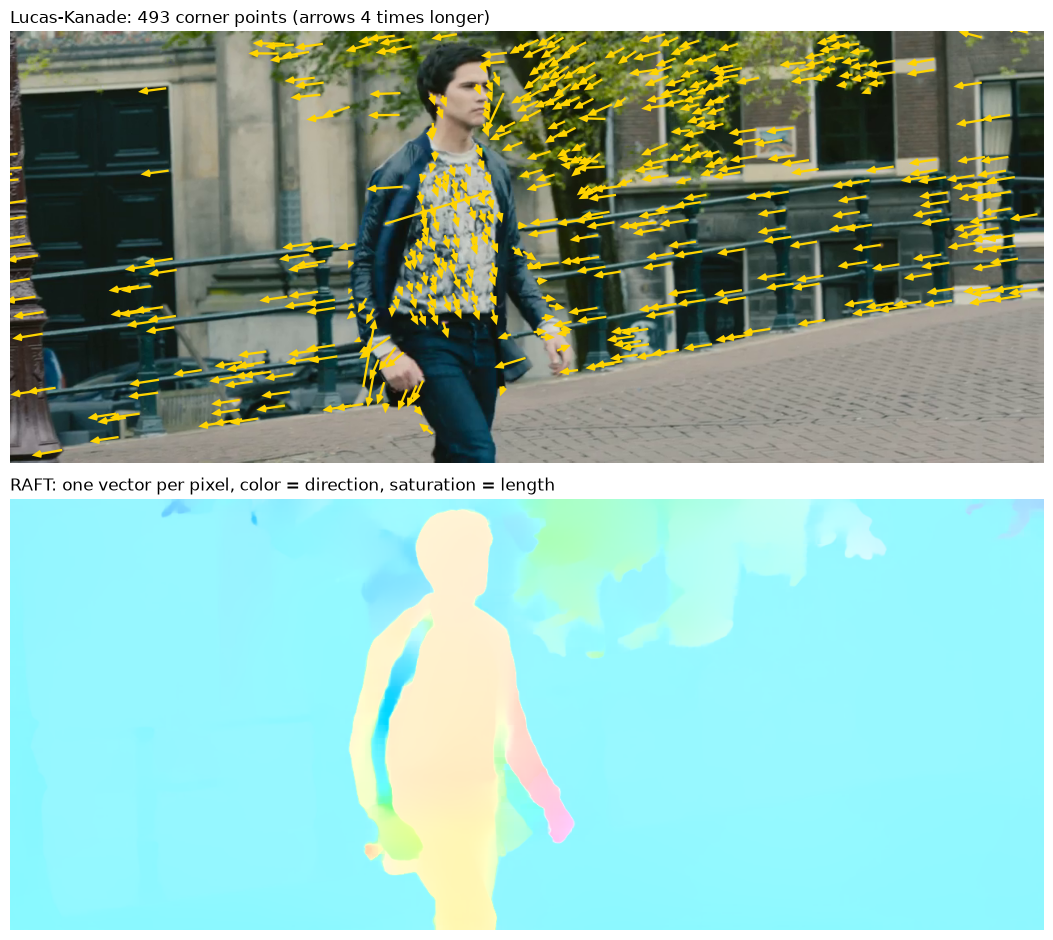

In [16]:
import torch
from torchvision.utils import flow_to_image

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 9.5))
ax1.imshow(f0)
ax1.quiver(p0[:, 0], p0[:, 1], v_lk[:, 0] * 4, v_lk[:, 1] * 4, angles="xy", scale_units="xy", scale=1,
           color="#ffd400", width=0.0022, headwidth=3.5, headlength=4)
ax1.set_title(f"Lucas-Kanade: {ok.sum()} corner points (arrows 4 times longer)", loc="left")
ax2.imshow(flow_to_image(torch.from_numpy(flow)).permute(1, 2, 0).numpy())
ax2.set_title("RAFT: one vector per pixel, color = direction, saturation = length", loc="left")
for ax in (ax1, ax2):
    ax.axis("off")
plt.tight_layout()
plt.show()

Where both methods have an estimate, they agree. The difference lies in the rest of the image:
RAFT fills in the flow on the pavement, the door, and Thom's jacket, where Lucas-Kanade has no
corners. Thom himself appears pale in the RAFT field, because the camera follows him: he moves
little in the image, while the background moves to the left. Lucas-Kanade is the
choice for a few points in real time; RAFT costs hundreds of times more and gives a dense field.

## Payoff: Finding the Fight Without Words

The subtitles of the film say nothing during the fight against the robots, and the CLIP search
of the book's section 3 finds at most three fight shots among its top five. Motion is a cheap
alternative. For every frame of the film, we measure the share of pixels that change by more than
20 gray values against the previous frame, and every sixth frame the median Lucas-Kanade flow of
up to 200 corners, which measures the camera motion. One pass over the film, cached after the
first run. For each shot we average the changed share and take the median of the flow.

In [17]:
# film_motion() in ch12_video.py runs the two measurements of this notebook over every frame:
# frame differencing with a gap of 1 (share of pixels that change by more than 20 gray values) and,
# every 6th frame, the median Lucas-Kanade flow of up to 200 Shi-Tomasi corners (pyramid, 15 x 15 window)
motion = film_motion()                 # array (frames, 3): changed share, camera u, camera v at 320 x 134

rows = []
for k, (a, b) in enumerate(shots):
    seg = motion[a + 1:b + 1] if b > a else motion[a:a + 1]
    flows = seg[np.isfinite(seg[:, 1]), 1:]
    camera = np.median(flows, axis=0) * 4 if len(flows) else np.array([np.nan, np.nan])   # in full-size pixels
    rows.append(dict(shot=k, first=a, last=b, activity=float(np.nanmean(seg[:, 0])),
                     u=float(camera[0]), v=float(camera[1]), fight=is_fight(a, b)))
ranked = sorted(rows, key=lambda r: -r["activity"])

n_fight = sum(r["fight"] for r in rows)
top = ranked[:10]
print_table([[i + 1, f"{tc(r['first'])} to {tc(r['last'])}", r["activity"], r["u"], r["v"],
              "fight" if r["fight"] else ""] for i, r in enumerate(top)],
            ["Rank", "Shot", "Changed pixels", "Camera u (px/frame)", "Camera v (px/frame)", ""],
            floatfmt=("", "", ".2f", ".1f", ".1f", ""))
moving_camera = sum(max(abs(r["u"]), abs(r["v"])) > 10 for r in top)
display_md(
    f"**{sum(r['fight'] for r in top)} of the 10 shots with the most motion are fight shots**, and "
    f"{sum(r['fight'] for r in ranked[:20])} of the top 20. Only {n_fight} of the {len(rows)} shots "
    f"({n_fight / len(rows):.0%}) belong to a fight sequence. In {moving_camera} of the top 10, the "
    f"camera moves by more than 10 pixels per frame."
)

|   Rank | Shot               |   Changed pixels |   Camera u (px/frame) |   Camera v (px/frame) |       |
|-------:|:-------------------|-----------------:|----------------------:|----------------------:|:------|
|      1 | 8:11.58 to 8:13.29 |             0.65 |                 -17.0 |                 -17.7 | fight |
|      2 | 7:49.54 to 7:53.08 |             0.61 |                  14.5 |                   1.3 | fight |
|      3 | 8:15.54 to 8:17.42 |             0.43 |                 -13.0 |                  -2.1 | fight |
|      4 | 7:48.33 to 7:49.50 |             0.41 |                  -2.3 |                  -0.2 | fight |
|      5 | 8:19.42 to 8:20.71 |             0.38 |                 -13.3 |                 -25.6 | fight |
|      6 | 8:17.46 to 8:19.38 |             0.36 |                  15.9 |                   2.6 | fight |
|      7 | 8:13.33 to 8:15.50 |             0.35 |                  30.9 |                  -1.2 | fight |
|      8 | 7:44.83 to 7:48.29 |             0.33 |                  -2.1 |                   1.9 | fight |
|      9 | 8:03.92 to 8:05.46 |             0.30 |                   2.8 |                   0.8 | fight |
|     10 | 8:22.38 to 8:23.67 |             0.30 |                   3.9 |                  -1.5 | fight |

**10 of the 10 shots with the most motion are fight shots**, and 14 of the top 20. Only 34 of the 140 shots (24%) belong to a fight sequence. In 6 of the top 10, the camera moves by more than 10 pixels per frame.

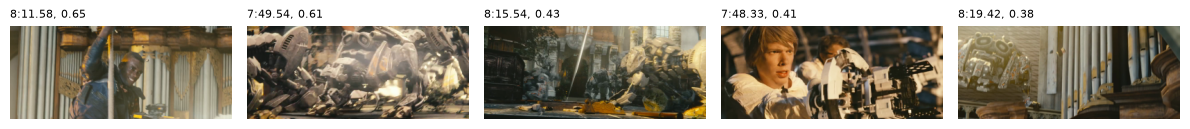

In [18]:
show_frames([frames((r["first"] + r["last"]) // 2, 1)[0] for r in top[:5]],
            [f"{tc(r['first'])}, {r['activity']:.2f}" for r in top[:5]], ncols=5, width=2.4)

The ten most active shots all come from the battle in the church. The camera columns show that
much of this activity is camera motion: fast pans and shaking. For "fast action", that is not a
flaw, because action is usually filmed with a moving camera.
A query for "a person walking past a static camera" would need the two columns separately: little
camera motion and some changed pixels.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Motion answers queries that neither the words nor the frames answer</strong><br>
A share of changed pixels per shot, computed with one subtraction per frame, finds the fight scenes of the film that the subtitles do not mention and that a single image cannot show. It does not know what a robot is; combining such cheap signals with image embeddings and the transcript is the subject of section 3 and demo ch12-03.
</div>

## Summary

- Background subtraction finds moving objects against a model of the empty scene. Without an
  empty frame, the first frame leaves ghosts, and a camera drift of a few pixels turns the whole
  image into foreground. A selective update cannot recover from that.
- Frame differencing adapts at once but sees mostly outlines. A larger gap shows more of the
  object, twice; three-frame differencing keeps the current position at the cost of a delay.
- The motion history image summarizes the last second of motion in one image, and its share,
  recency, and center are features for retrieval.
- Lucas-Kanade solves a 2 by 2 system per window. It works where both eigenvalues are large, at
  corners and in texture, and it needs a pyramid for motions of more than about one pixel.
- RAFT gives a vector for every pixel and agrees with Lucas-Kanade at the corners, at a cost of
  hundreds of times more computation.
- A simple motion feature ranks the fight shots of the film at the top.

## Try it yourself

1. **The threshold.** Change `TAU` to 15 and 60 and rerun the background subtraction. How do the
   ghost and the noise change? Which value would you choose, and on what basis?
2. **Shadows and chromaticity.** Convert the RGB frames of the bridge shot to HSV with
   `cv2.cvtColor(..., cv2.COLOR_RGB2HSV)` and difference only the hue and saturation. Which parts
   of the actors disappear, and why?
3. **Camera motion as a query.** Use the `rows` of the payoff to find the shots with the strongest
   horizontal camera motion (`u`) and little vertical motion. Look at their middle frames: are
   they pans?